# Eigenfaces with PCA

Principal component analysis on 400 face photos. Each 64×64 image has 4,096 pixels. PCA squeezes it into 20 numbers, rebuilds the face from them, and shows what those numbers capture: the main ways faces differ from the average face.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_olivetti_faces
from sklearn.decomposition import PCA

plt.rcParams['figure.dpi'] = 110

## Data

The Olivetti faces: 400 grayscale photos of 40 people, 10 photos each, 64×64 pixels, scaled 0 to 1. Each row of `X` is one face, flattened to 4,096 pixel values.

In [2]:
faces = fetch_olivetti_faces(shuffle=False)
X = pd.DataFrame(faces.data)
y = pd.Series(faces.target, name='person')
print(X.shape, y.nunique(), 'people')

(400, 4096) 40 people


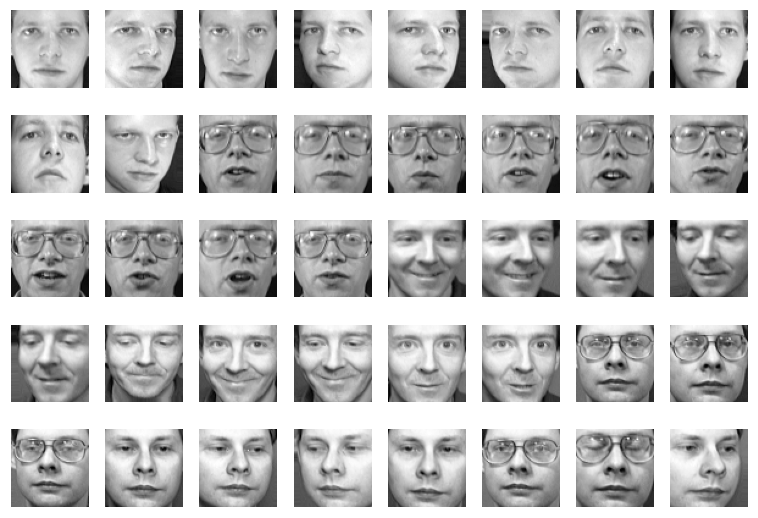

In [3]:
def plot_faces(pixels, n_rows, n_cols, titles=None, size=(7, 5)):
    """Show the first n_rows * n_cols rows of `pixels` as a grid of 64x64 images."""
    pixels = np.asarray(pixels)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=size)
    for i, ax in enumerate(np.atleast_1d(axes).flat):
        ax.imshow(pixels[i].reshape(64, 64), cmap='gray')
        if titles is not None:
            ax.set_title(titles[i], fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

plot_faces(X, 5, 8)

## The mean face

The average of all 400 faces. PCA describes every face as this mean plus a weighted sum of a few directions of variation.

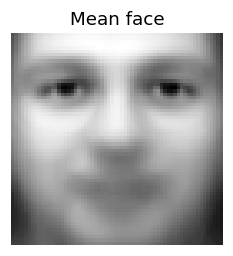

In [4]:
mean_X = X.mean(axis=0)
plt.figure(figsize=(2.5, 2.5))
plt.imshow(mean_X.values.reshape(64, 64), cmap='gray')
plt.axis('off')
plt.title('Mean face')
plt.show()

## Center the data

Subtracting the mean face from every face leaves only what makes each one different.

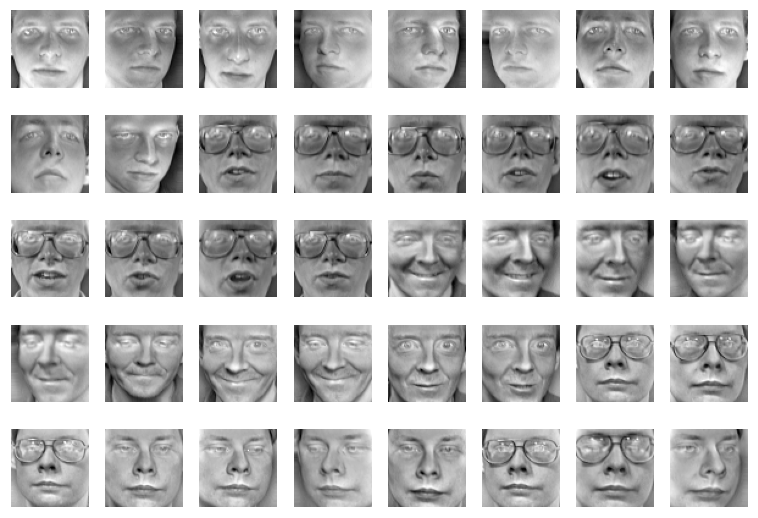

In [5]:
zeromean_X = X - mean_X
plot_faces(zeromean_X, 5, 8)

## Fit PCA with 20 components

The input is centered but not scaled. Twenty components take each face from 4,096 numbers down to 20.

In [6]:
pca = PCA(n_components=20)
pca.fit(zeromean_X)
print(f'Variance explained by 20 components: {pca.explained_variance_ratio_.sum():.1%}')
print(f'First component alone: {pca.explained_variance_ratio_[0]:.1%}')

Variance explained by 20 components: 76.3%
First component alone: 23.8%


## Eigenfaces

The principal components, drawn as images. Each one is a direction of variation across the faces: lighting from one side, a wider forehead, glasses.

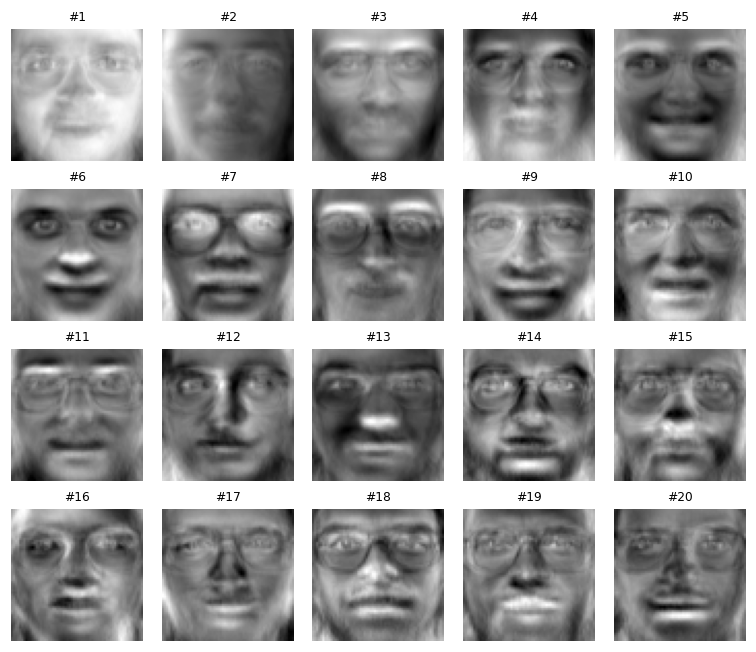

In [7]:
eigenfaces = pca.components_
plot_faces(eigenfaces, 4, 5, titles=[f'#{i + 1}' for i in range(20)], size=(7, 6))

## Reconstruct the faces

Each face is now a 20-number weight vector. Multiplying the weights by the eigenfaces and adding the mean face back gives an approximation of the original.

Weights: (400, 20)


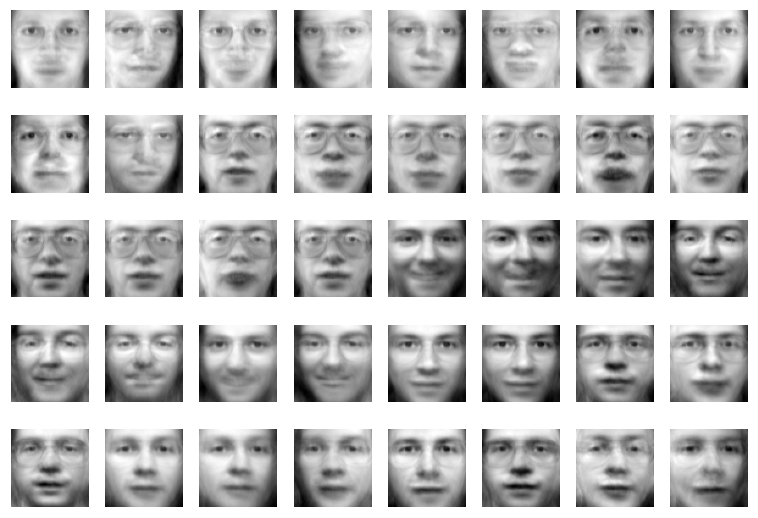

In [8]:
weights = pca.transform(zeromean_X)
print('Weights:', weights.shape)

reconstructed_X = weights @ eigenfaces + mean_X.values
plot_faces(reconstructed_X, 5, 8)

## Reconstruction error

The difference between each original face and its reconstruction, and the largest L2 norm of that difference across all 400 faces. A second model with 150 components shows how much more detail the extra directions recover.

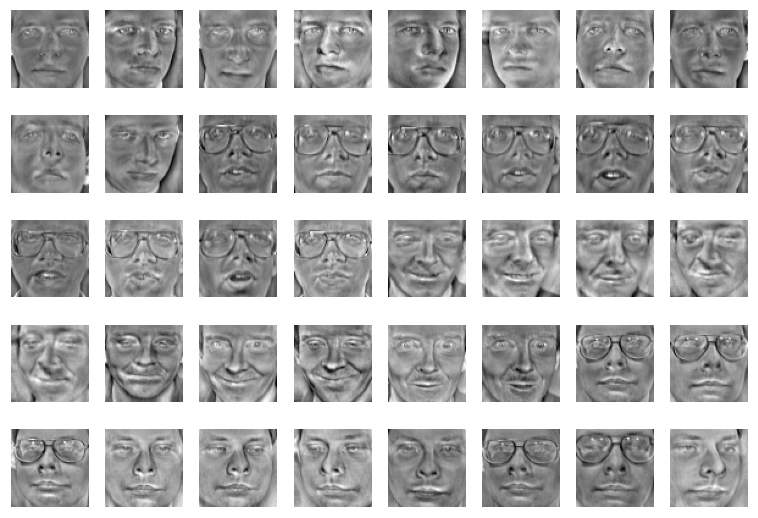

Max L2 error with  20 components: 6.254
Max L2 error with 150 components: 2.166


In [9]:
diff = X.values - reconstructed_X
plot_faces(diff, 5, 8)

norm_20 = np.linalg.norm(diff, axis=1).max()

pca_150 = PCA(n_components=150).fit(zeromean_X)
reconstructed_150 = pca_150.inverse_transform(pca_150.transform(zeromean_X)) + mean_X.values
norm_150 = np.linalg.norm(X.values - reconstructed_150, axis=1).max()

print(f'Max L2 error with  20 components: {norm_20:.3f}')
print(f'Max L2 error with 150 components: {norm_150:.3f}')

## Walking along an eigenface

Starting from the mean face and moving along one eigenface, from −2 to +2 scaled steps, shows what that direction encodes.

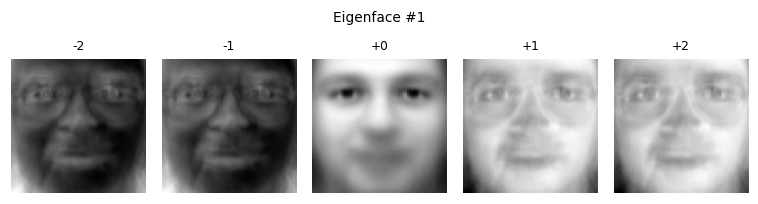

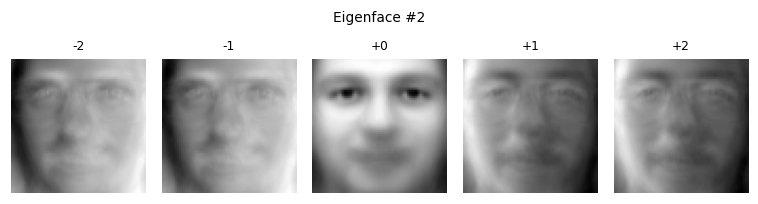

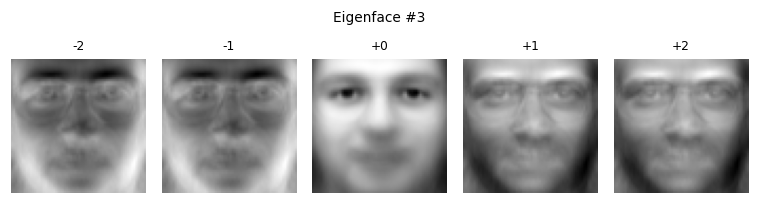

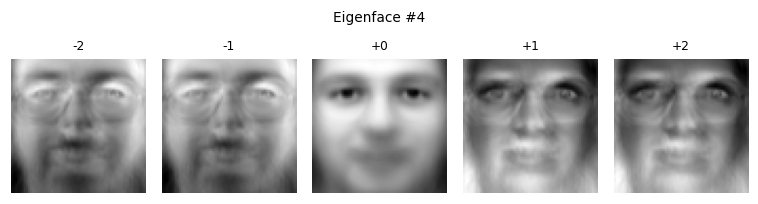

In [10]:
def walk_along_eigenface(k):
    step = pca.singular_values_[k] * eigenfaces[k]
    path = [mean_X.values + m * step for m in (-2, -1, 0, 1, 2)]
    fig, axes = plt.subplots(1, 5, figsize=(7, 1.9))
    for ax, face, m in zip(axes, path, (-2, -1, 0, 1, 2)):
        ax.imshow(face.reshape(64, 64), cmap='gray')
        ax.set_title(f'{m:+d}', fontsize=8)
        ax.axis('off')
    fig.suptitle(f'Eigenface #{k + 1}', fontsize=9)
    plt.tight_layout()
    plt.show()

for k in range(4):
    walk_along_eigenface(k)